In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

In [2]:
import os
import requests
from tqdm import tqdm

url = "https://zenodo.org/records/10845026/files/Galaxy10_DECals.h5"
ruta_destino = "data/Galaxy10_DECals.h5"

if not os.path.exists(ruta_destino):
    respuesta = requests.get(url, stream=True)
    tamano_total = int(respuesta.headers.get('content-length', 0))

    with open(ruta_destino, 'wb') as archivo, tqdm(
        desc=ruta_destino,
        total=tamano_total,
        unit='B',
        unit_scale=True,
        unit_divisor=1024,
    ) as barra:
        for datos in respuesta.iter_content(chunk_size=1024):
            archivo.write(datos)
            barra.update(len(datos))

In [3]:
import h5py

with h5py.File('data/Galaxy10_DECals.h5', 'r') as F:
    images = np.array(F['images'])
    labels = np.array(F['ans'])
    

In [5]:
np.unique(labels)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [23]:
np.unique_counts(labels)

UniqueCountsResult(values=array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), counts=array([1081, 1853, 2645, 2027,  334, 2043, 1829, 2628, 1423, 1873]))

Galaxy10 dataset (17736 images)
- Class 0 (1081 images): Disturbed Galaxies
- Class 1 (1853 images): Merging Galaxies
- Class 2 (2645 images): Round Smooth Galaxies
- Class 3 (2027 images): In-between Round Smooth Galaxies
- Class 4 ( 334 images): Cigar Shaped Smooth Galaxies
- Class 5 (2043 images): Barred Spiral Galaxies
- Class 6 (1829 images): Unbarred Tight Spiral Galaxies
- Class 7 (2628 images): Unbarred Loose Spiral Galaxies
- Class 8 (1423 images): Edge-on Galaxies without Bulge
- Class 9 (1873 images): Edge-on Galaxies with Bulge

(taken from the original website)

In [14]:
label_names = [
    "Disturbed Galaxies",
    "Merging Galaxies",
    "Round Smooth Galaxies",
    "In-between Round Smooth Galaxies",
    "Cigar Shaped Smooth Galaxies",
    "Barred Spiral Galaxies",
    "Unbarred Tight Spiral Galaxies",
    "Unbarred Loose Spiral Galaxies",
    "Edge-on Galaxies without Bulge",
    "Edge-on Galaxies with Bulge"
]

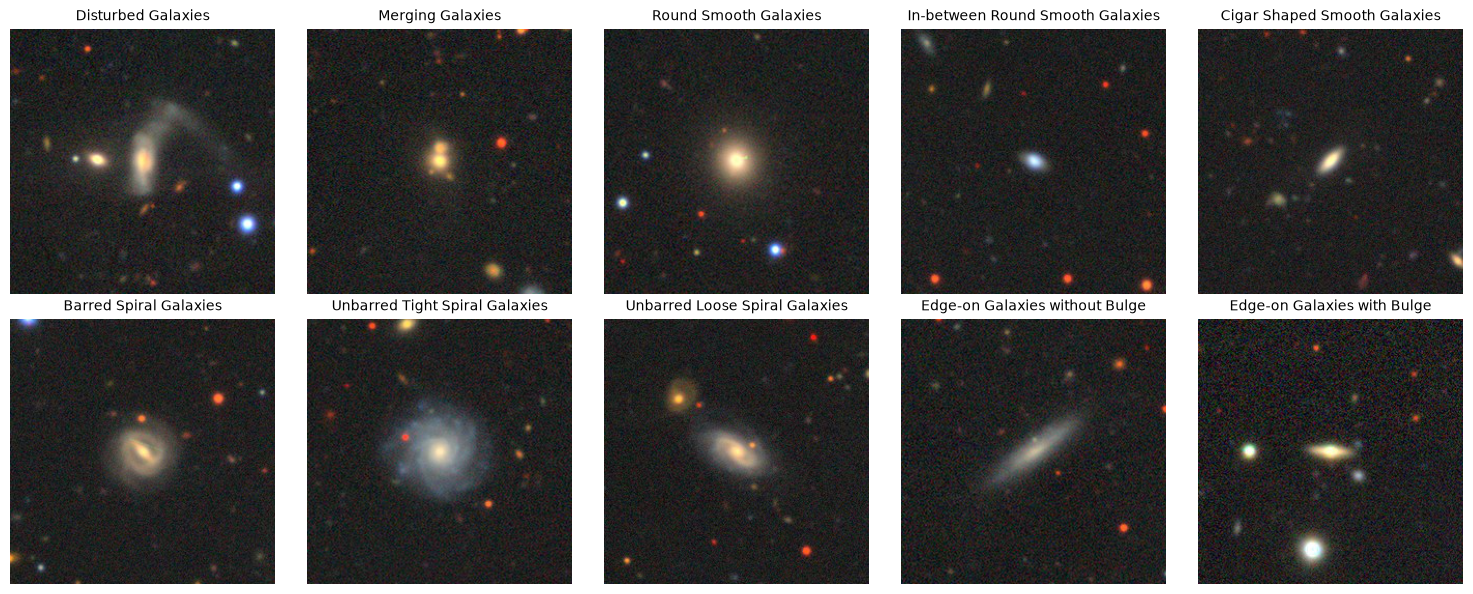

In [19]:
clases_unicas = np.unique(labels)
filas = 2
columnas = (len(clases_unicas) + filas - 1) // filas

fig, axes = plt.subplots(filas, columnas, figsize=(15, 6))
axes = axes.flatten()

for i, clase in enumerate(clases_unicas):
    idx = np.where(labels == clase)[0][0]
    
    axes[i].imshow(images[idx])
    axes[i].set_title(label_names[clase], fontsize=10)
    axes[i].axis('off')

for j in range(len(clases_unicas), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [7]:
images.shape

(17736, 256, 256, 3)

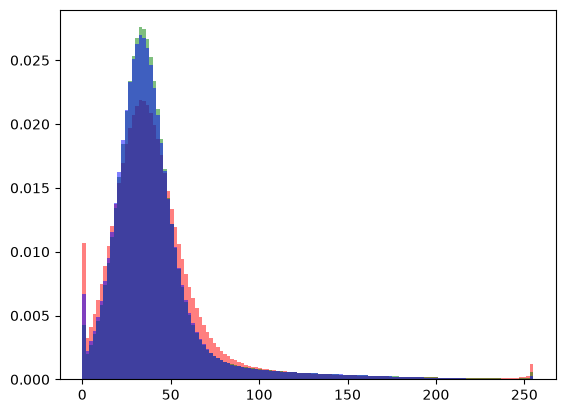

In [8]:
import matplotlib.pyplot as plt

canal_0 = images[:, :, :, 0].flatten()
canal_1 = images[:, :, :, 1].flatten()
canal_2 = images[:, :, :, 2].flatten()

plt.hist(canal_0, bins=128, color='red', alpha=0.5, density=True)
plt.hist(canal_1, bins=128, color='green', alpha=0.5, density=True)
plt.hist(canal_2, bins=128, color='blue', alpha=0.5, density=True)

plt.show()

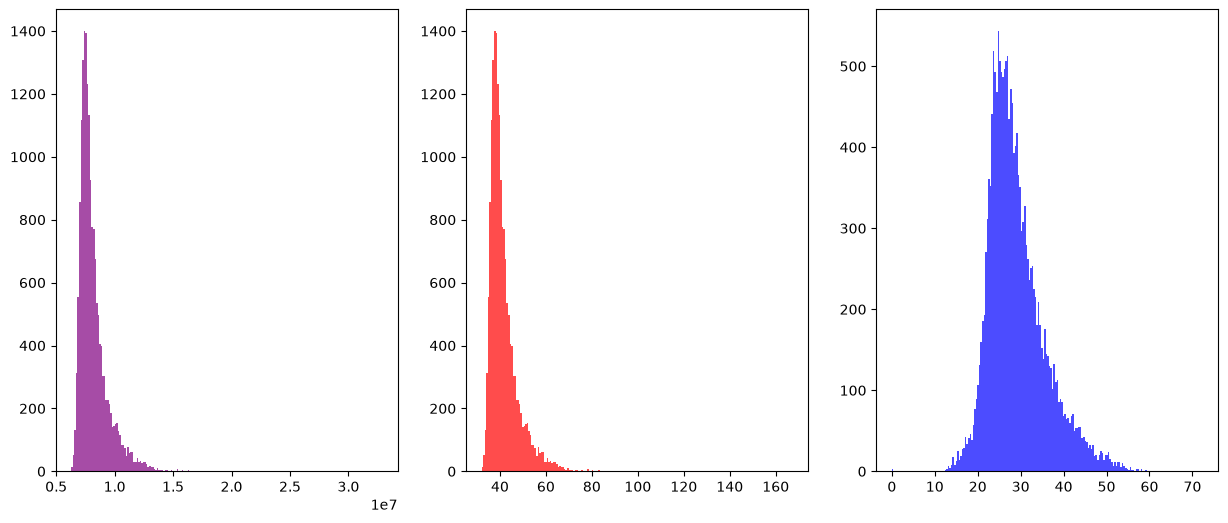

In [22]:
umas_por_imagen = np.empty(len(images))
mean_por_imagen = np.empty(len(images))
std_por_imagen = np.empty(len(images))

for i in range(len(images)):
    sumas_por_imagen[i] = images[i].sum()
    mean_por_imagen[i] = images[i].mean()
    std_por_imagen[i] = images[i].std()

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].hist(sumas_por_imagen, bins=200, color='purple', alpha=0.7)
axes[1].hist(mean_por_imagen, bins=200, color='red', alpha=0.7)
axes[2].hist(std_por_imagen, bins=200, color='blue', alpha=0.7)

plt.show()

indices_vacios = np.where(sumas_por_imagen == 0)[0]

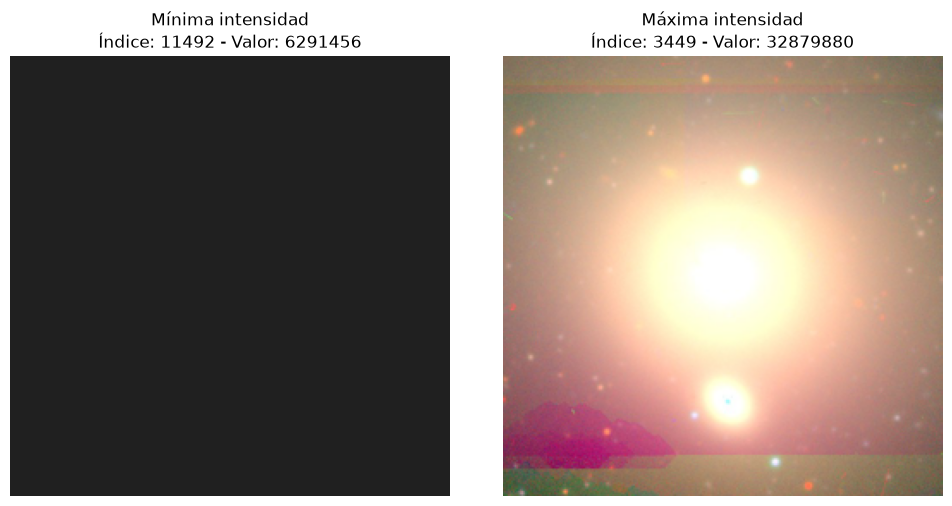


Ratio between brightest and darkest images 5.226116180419922


In [27]:
idx_min = np.argmin(sumas_por_imagen)
idx_max = np.argmax(sumas_por_imagen)
val_min = min(sumas_por_imagen)
val_max = max(sumas_por_imagen)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(images[idx_min])
axes[0].set_title(f"Mínima intensidad\nÍndice: {idx_min} - Valor: {val_min}")
axes[0].axis('off')

axes[1].imshow(images[idx_max])
axes[1].set_title(f"Máxima intensidad\nÍndice: {idx_max} - Valor: {val_max}")
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"\nRatio between brightest and darkest images {val_max/val_min}")